# HW4.a + HW4.5 add-on: everything the handout asks for that the first notebook did not cover
Runtime: **A100** (same as your last run), Internet ON. Run top to bottom, about 50 min (~4-5 compute units).
Adds: save/reload + custom inference, vLLM demo with your own prompt, plain HF **pipeline** baseline, Part B max-batch per technique,
accumulation vs same effective batch (same optimizer steps), best combination, measured KV curve + memory-bound longest context,
figures and the Table HW4.5.1 / HW4.1 rows. Part C is optional and skipped.

## 0. Setup

In [1]:
!nvidia-smi -L
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!pip -q install transformers scikit-learn pandas matplotlib bitsandbytes datasets
import torch, transformers; print('torch', torch.__version__, '| transformers', transformers.__version__)
!mkdir -p /content/hw45/results

GPU 0: Tesla T4 (UUID: GPU-45a3688f-91da-aece-1fc4-c05b615f9aa2)
name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07
torch 2.11.0+cu130 | transformers 5.22.0


In [2]:
%%writefile /content/hw45/config.py
"""Shared settings. FILL IN the values marked TODO from your original HW4 code
so every run uses the exact same data slice, split and fine-tune recipe."""
import os

# Must be IDENTICAL to HW4.a: same Twitter sentiment data, same rows, same split, same SEED.
# ---- TODO: copy these from your HW4.a code -------------------------------
# Hugging Face source (used if HF_DATASET is set); otherwise falls back to the CSV at DATA_PATH
HF_DATASET = "cardiffnlp/tweet_eval"          # TODO e.g. "cardiffnlp/tweet_eval" -- MUST be the dataset you used in HW4.a
HF_CONFIG = "sentiment"           # TODO e.g. "sentiment"
HF_SPLIT = "train"         # TODO the split HW4.a sliced rows from
DATA_PATH = os.environ.get("HW4_DATA", "data/train.csv")  # CSV fallback
TEXT_COL = "text"          # TODO column holding the input text
LABEL_COL = "label"        # TODO column holding the class label
SLICE = (638, 5638)        # course SLICE=638 (6638 % 1000): 5,000 consecutive rows 638..5637
SEED = 6638                # course SEED (student ID last 4)
MODEL_NAME = "bert-base-uncased"  # TODO the BERT checkpoint used in HW4
MAX_LEN = 128              # TODO
LR = 2e-5                  # TODO
EPOCHS = 3                 # TODO
BASE_BATCH = 16            # TODO the HW4.a batch size (the reference run)
WEIGHT_DECAY = 0.01
# --------------------------------------------------------------------------

SPLIT = (0.70, 0.15, 0.15)  # train / val / test
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)


Writing /content/hw45/config.py


In [3]:
%%writefile /content/hw45/data.py
"""Data loading: fixed 5,000-row slice, seeded 70/15/15 split, tokenization."""
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset

import config as C


class TextDS(Dataset):
    def __init__(self, enc, labels):
        self.enc, self.labels = enc, labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item


def load_frame(smoke=False):
    if smoke:  # synthetic data so the pipeline can be tested without your CSV
        rng = np.random.RandomState(0)
        words = ["good", "bad", "ok", "fine", "poor", "great", "awful", "nice"]
        n = 300
        labels = rng.randint(0, 3, n)
        texts = [" ".join(rng.choice(words, 12)) + f" {l}" for l in labels]
        return pd.DataFrame({C.TEXT_COL: texts, C.LABEL_COL: labels})
    if C.HF_DATASET:
        from datasets import load_dataset
        df = load_dataset(C.HF_DATASET, C.HF_CONFIG, split=C.HF_SPLIT).to_pandas()
        src = f"{C.HF_DATASET}/{C.HF_CONFIG}/{C.HF_SPLIT}"
    else:
        df = pd.read_csv(C.DATA_PATH); src = C.DATA_PATH
    a, b = C.SLICE
    df = df.iloc[a:b].reset_index(drop=True)
    print(f"[data] using rows {a}..{b - 1} of {src} ({len(df)} rows)")
    return df


def split_frame(df):
    rng = np.random.RandomState(C.SEED)
    idx = rng.permutation(len(df))
    n_tr = int(C.SPLIT[0] * len(df))
    n_va = int(C.SPLIT[1] * len(df))
    parts = (idx[:n_tr], idx[n_tr:n_tr + n_va], idx[n_tr + n_va:])
    return [df.iloc[p].reset_index(drop=True) for p in parts]


def make_datasets(tokenizer, smoke=False):
    df = load_frame(smoke)
    tr, va, te = split_frame(df)
    classes = sorted(df[C.LABEL_COL].unique().tolist())
    cmap = {c: i for i, c in enumerate(classes)}

    def enc(d):
        e = tokenizer(d[C.TEXT_COL].astype(str).tolist(), truncation=True,
                      padding="max_length", max_length=C.MAX_LEN if not smoke else 32,
                      return_tensors="pt")
        y = torch.tensor(d[C.LABEL_COL].map(cmap).values, dtype=torch.long)
        return TextDS(e, y)

    return enc(tr), enc(va), enc(te), classes


Writing /content/hw45/data.py


In [4]:
%%writefile /content/hw45/train_bert.py
"""BERT fine-tune with the HW4.5 memory/throughput knobs.

Examples:
  python train_bert.py --tag baseline
  python train_bert.py --batch-size 64 --amp --tag amp64
  python train_bert.py --grad-ckpt --accum-steps 4 --optim adamw8bit --tag combo
  python train_bert.py --smoke --tag smoke        # CPU test, tiny random BERT
Writes results/<tag>.json. Exit code 3 + {"oom": true} JSON on CUDA OOM.
"""
import argparse, json, os, time

import numpy as np
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, BertConfig, BertForSequenceClassification, AutoModelForSequenceClassification

import config as C
from data import make_datasets


def get_args(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("--batch-size", type=int, default=C.BASE_BATCH)
    p.add_argument("--epochs", type=int, default=C.EPOCHS)
    p.add_argument("--amp", action="store_true", help="mixed precision")
    p.add_argument("--amp-dtype", choices=["fp16", "bf16"], default="fp16")
    p.add_argument("--grad-ckpt", action="store_true")
    p.add_argument("--accum-steps", type=int, default=1)
    p.add_argument("--optim", choices=["adamw", "adamw8bit"], default="adamw")
    p.add_argument("--tag", default="run")
    p.add_argument("--smoke", action="store_true")
    p.add_argument("--max-train-steps", type=int, default=0, help="stop after N optimizer steps (for scaling probes)")
    p.add_argument("--no-eval", action="store_true", help="skip val/test (scaling probes)")
    p.add_argument("--out-dir", default=C.RESULTS_DIR)
    p.add_argument("--save-dir", default=None, help="save final model + tokenizer here (HW4.a: save and reload)")
    return p.parse_args(argv)


def build_model(num_labels, smoke):
    if smoke:
        cfg = BertConfig(hidden_size=64, num_hidden_layers=2, num_attention_heads=2,
                         intermediate_size=128, vocab_size=30522, num_labels=num_labels)
        return BertForSequenceClassification(cfg)
    return AutoModelForSequenceClassification.from_pretrained(C.MODEL_NAME, num_labels=num_labels)


def build_optimizer(model, kind):
    if kind == "adamw8bit":
        import bitsandbytes as bnb
        return bnb.optim.AdamW8bit(model.parameters(), lr=C.LR, weight_decay=C.WEIGHT_DECAY)
    return torch.optim.AdamW(model.parameters(), lr=C.LR, weight_decay=C.WEIGHT_DECAY)


@torch.no_grad()
def evaluate(model, loader, dev, amp_ctx):
    model.eval()
    tot, n, preds, ys = 0.0, 0, [], []
    for b in loader:
        b = {k: v.to(dev) for k, v in b.items()}
        with amp_ctx():
            out = model(**b)
        tot += out.loss.item() * len(b["labels"]); n += len(b["labels"])
        preds.append(out.logits.argmax(-1).cpu()); ys.append(b["labels"].cpu())
    p, y = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return tot / n, float((p == y).mean()), p, y


def main(argv=None):
    a = get_args(argv)
    torch.manual_seed(C.SEED); np.random.seed(C.SEED)
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    use_cuda = dev.type == "cuda"
    tok = None if a.smoke else AutoTokenizer.from_pretrained(C.MODEL_NAME)
    if a.smoke:  # tiny fake tokenizer: hash words into vocab
        class FakeTok:
            def __call__(self, texts, truncation, padding, max_length, return_tensors):
                ids = torch.zeros(len(texts), max_length, dtype=torch.long)
                for i, t in enumerate(texts):
                    for j, w in enumerate(t.split()[:max_length]):
                        ids[i, j] = (hash(w) % 30000) + 1
                return {"input_ids": ids, "attention_mask": (ids > 0).long()}
        tok = FakeTok()

    tr, va, te, classes = make_datasets(tok, a.smoke)
    result = {"tag": a.tag, "args": vars(a), "device": str(dev), "n_train": len(tr),
              "n_val": len(va), "n_test": len(te), "classes": [str(c) for c in classes]}
    if use_cuda:
        result["gpu"] = torch.cuda.get_device_name(0)
        torch.cuda.reset_peak_memory_stats()

    try:
        model = build_model(len(classes), a.smoke).to(dev)
        if a.grad_ckpt:
            model.gradient_checkpointing_enable()
        opt = build_optimizer(model, a.optim)
        dtype = torch.bfloat16 if a.amp_dtype == "bf16" else torch.float16
        amp_on = a.amp and use_cuda
        use_scaler = amp_on and dtype == torch.float16
        scaler = torch.amp.GradScaler("cuda") if use_scaler else None
        amp_ctx = (lambda: torch.autocast("cuda", dtype=dtype)) if amp_on else (lambda: torch.autocast("cpu", enabled=False))

        tl = DataLoader(tr, batch_size=a.batch_size, shuffle=True, drop_last=True,
                        generator=torch.Generator().manual_seed(C.SEED))
        vl = DataLoader(va, batch_size=64); tel = DataLoader(te, batch_size=64)

        hist, best, best_state, steps = [], (-1, 0), None, 0
        t_start = time.time(); train_time = 0.0; samples = 0
        stop = False
        for ep in range(1, a.epochs + 1):
            model.train()
            if use_cuda: torch.cuda.synchronize()
            t0 = time.time(); run, cnt = 0.0, 0
            opt.zero_grad(set_to_none=True)
            for i, b in enumerate(tl, 1):
                b = {k: v.to(dev) for k, v in b.items()}
                with amp_ctx():
                    loss = model(**b).loss / a.accum_steps
                (scaler.scale(loss) if scaler else loss).backward()
                run += loss.item() * a.accum_steps * len(b["labels"]); cnt += len(b["labels"])
                samples += len(b["labels"])
                if i % a.accum_steps == 0:
                    if scaler:
                        scaler.step(opt); scaler.update()
                    else:
                        opt.step()
                    opt.zero_grad(set_to_none=True); steps += 1
                    if a.max_train_steps and steps >= a.max_train_steps:
                        stop = True; break
            if use_cuda: torch.cuda.synchronize()
            ep_time = time.time() - t0; train_time += ep_time
            rec = {"epoch": ep, "train_loss": run / max(cnt, 1), "epoch_time_s": ep_time,
                   "samples_per_s": cnt / ep_time}
            if not a.no_eval:
                vloss, vacc, _, _ = evaluate(model, vl, dev, amp_ctx)
                rec.update(val_loss=vloss, val_acc=vacc)
                if vacc > best[0]:
                    best = (vacc, ep)
            hist.append(rec); print(json.dumps(rec))
            if stop: break

        result.update(history=hist, train_time_s=train_time, wall_clock_s=time.time() - t_start,
                      samples_per_s=samples / train_time, optimizer_steps=steps,
                      effective_batch=a.batch_size * a.accum_steps)
        if use_cuda:
            result["peak_mem_mb"] = torch.cuda.max_memory_allocated() / 2**20
        if a.save_dir:  # after peak memory is read, so saving never affects the measurement
            os.makedirs(a.save_dir, exist_ok=True)
            model.save_pretrained(a.save_dir)
            if not a.smoke: tok.save_pretrained(a.save_dir)
            result["saved_to"] = a.save_dir
        if not a.no_eval:
            result["best_epoch"] = best[1]; result["best_val_acc"] = best[0]
            tloss, tacc, p, y = evaluate(model, tel, dev, amp_ctx)
            result.update(test_loss=tloss, test_acc=tacc)
            from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
            cm = confusion_matrix(y, p, labels=list(range(len(classes))))
            pr, rc, f1, sup = precision_recall_fscore_support(y, p, labels=list(range(len(classes))), zero_division=0)
            result["confusion_matrix"] = cm.tolist()
            result["per_class"] = [{"class": str(classes[i]), "precision": float(pr[i]), "recall": float(rc[i]),
                                    "f1": float(f1[i]), "support": int(sup[i])} for i in range(len(classes))]
            worst = int(np.argmin(f1)); result["worst_class"] = str(classes[worst])
            wrong = np.where((y == worst) & (p != y))[0][:5].tolist()
            texts = te_texts(a)
            result["misclassified_examples"] = [{"text": texts[j] if texts else f"test idx {j}",
                                                 "true": str(classes[int(y[j])]), "pred": str(classes[int(p[j])])}
                                                for j in wrong]
        result["oom"] = False
        code = 0
    except torch.cuda.OutOfMemoryError:
        result["oom"] = True; code = 3
        print("CUDA OOM")

    path = os.path.join(a.out_dir, f"{a.tag}.json")
    os.makedirs(a.out_dir, exist_ok=True)
    with open(path, "w") as f:
        json.dump(result, f, indent=2)
    print("wrote", path)
    return code


def te_texts(a):
    """Test-set raw texts (same split as data.py) for error analysis."""
    from data import load_frame, split_frame
    return split_frame(load_frame(a.smoke))[2][C.TEXT_COL].astype(str).tolist()


if __name__ == "__main__":
    raise SystemExit(main())


Writing /content/hw45/train_bert.py


In [5]:
%%writefile /content/hw45/batch_scaling.py
"""Part A: batch-size scaling until OOM. One subprocess per batch size so an
OOM never poisons the next run. Reports throughput, peak memory, time/epoch."""
import argparse, json, os, subprocess, sys

import config as C


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--start", type=int, default=8)
    p.add_argument("--max", type=int, default=4096)
    p.add_argument("--epochs", type=int, default=1)
    p.add_argument("--extra", default="", help='extra train_bert flags, e.g. "--amp"')
    p.add_argument("--prefix", default="scale")
    p.add_argument("--smoke", action="store_true")
    a = p.parse_args()

    rows, bs = [], a.start
    while bs <= a.max:
        tag = f"{a.prefix}_bs{bs}"
        cmd = [sys.executable, "train_bert.py", "--batch-size", str(bs), "--epochs", str(a.epochs),
               "--tag", tag, "--no-eval"] + a.extra.split() + (["--smoke"] if a.smoke else [])
        print(">>", " ".join(cmd), flush=True)
        rc = subprocess.run(cmd).returncode
        path = os.path.join(C.RESULTS_DIR, f"{tag}.json")
        r = json.load(open(path)) if os.path.exists(path) else {"oom": True}
        if rc != 0 or r.get("oom"):
            rows.append({"batch_size": bs, "oom": True}); print(f"OOM/failure at batch {bs}"); break
        rows.append({"batch_size": bs, "oom": False, "samples_per_s": r["samples_per_s"],
                     "peak_mem_mb": r.get("peak_mem_mb"), "time_per_epoch_s": r["train_time_s"] / a.epochs})
        bs *= 2

    out = os.path.join(C.RESULTS_DIR, f"{a.prefix}_summary.json")
    json.dump(rows, open(out, "w"), indent=2)
    print(f"\n{'batch':>6} {'samples/s':>10} {'peak MB':>9} {'s/epoch':>8}")
    for r in rows:
        print(f"{r['batch_size']:>6} " + ("OOM" if r["oom"] else
              f"{r['samples_per_s']:>10.1f} {r['peak_mem_mb'] or 0:>9.0f} {r['time_per_epoch_s']:>8.1f}"))

    ok = [r for r in rows if not r["oom"]]
    if ok:
        import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
        fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
        x = [r["batch_size"] for r in ok]
        ax[0].plot(x, [r["samples_per_s"] for r in ok], "o-"); ax[0].set_xscale("log", base=2)
        ax[0].set_xlabel("batch size"); ax[0].set_ylabel("samples/s"); ax[0].set_title("Throughput")
        ax[1].plot(x, [r["peak_mem_mb"] or 0 for r in ok], "o-"); ax[1].set_xscale("log", base=2)
        ax[1].set_xlabel("batch size"); ax[1].set_ylabel("peak MB"); ax[1].set_title("Peak GPU memory")
        fig.tight_layout(); fig.savefig(os.path.join(C.RESULTS_DIR, f"{a.prefix}_plot.png"), dpi=150)


if __name__ == "__main__":
    main()


Writing /content/hw45/batch_scaling.py


In [6]:
%%writefile /content/hw45/part_b_full.py
"""Part B (complete): per-technique max batch size + accuracy, gradient accumulation vs the same effective
batch at the same number of optimizer steps, and the best combination.

  python part_b_full.py            # ~25-30 min on an A100; use --smoke for a CPU test

Steps
 1. For each technique (amp, grad_ckpt, adamw8bit): scale batch by powers of two until OOM (batch_scaling.py),
    then train 3 epochs WITH evaluation at the largest batch that ran -> max batch, throughput, peak memory, accuracy.
 2. Accumulation: micro-batch 16 x accum {4,16} vs plain batch {64,256}: same effective batch, same
    number of optimizer steps -> wall-clock, peak memory, accuracy.
 3. Combination: AMP + 8-bit AdamW (no checkpointing) at batch 16 and at the AMP max batch.
Everything is written to results/part_b_full.json.
"""
import argparse, json, os, subprocess, sys

import config as C

TECH = {"amp": ["--amp"], "grad_ckpt": ["--grad-ckpt"], "adamw8bit": ["--optim", "adamw8bit"]}


def sh(cmd):
    print(">>", " ".join(cmd), flush=True)
    return subprocess.run(cmd).returncode


def load(tag):
    p = os.path.join(C.RESULTS_DIR, f"{tag}.json")
    return json.load(open(p)) if os.path.exists(p) else {"oom": True}


def train(tag, bs, flags, smoke, epochs=None):
    cmd = [sys.executable, "train_bert.py", "--tag", tag, "--batch-size", str(bs)] + flags
    if epochs: cmd += ["--epochs", str(epochs)]
    if smoke: cmd += ["--smoke"]
    sh(cmd)
    r = load(tag)
    if r.get("oom"): return {"tag": tag, "batch": bs, "oom": True}
    return {"tag": tag, "batch": bs, "effective_batch": r["effective_batch"], "oom": False,
            "samples_per_s": r["samples_per_s"], "peak_mem_mb": r.get("peak_mem_mb"),
            "train_time_s": r["train_time_s"], "optimizer_steps": r["optimizer_steps"],
            "best_val_acc": r.get("best_val_acc"), "test_acc": r.get("test_acc"),
            "final_val_acc": r["history"][-1].get("val_acc")}


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--smoke", action="store_true")
    p.add_argument("--start", type=int, default=16)
    p.add_argument("--max", type=int, default=4096)
    p.add_argument("--epochs", type=int, default=None)
    a = p.parse_args()
    out = {"max_batch": {}, "accum": [], "combo": []}

    # 1. max batch per technique
    for name, flags in TECH.items():
        prefix = f"scan_{name}"
        sh([sys.executable, "batch_scaling.py", "--start", str(a.start), "--max", str(a.max),
            "--prefix", prefix, "--extra=" + " ".join(flags)] + (["--smoke"] if a.smoke else []))
        rows = json.load(open(os.path.join(C.RESULTS_DIR, f"{prefix}_summary.json")))
        ok = [r for r in rows if not r["oom"]]
        first_oom = next((r["batch_size"] for r in rows if r["oom"]), None)
        if not ok:
            out["max_batch"][name] = {"error": "no batch size ran", "oom": True, "batch": 0}; continue
        mx = ok[-1]["batch_size"]
        res = train(f"maxbatch_{name}", mx, flags, a.smoke, a.epochs)
        res.update(scan=ok, first_oom_batch=first_oom)
        out["max_batch"][name] = res

    # 2. gradient accumulation vs same effective batch, same number of optimizer steps
    for accum in (4, 16):
        eff = 16 * accum
        out["accum"].append({"effective_batch": eff,
                             "accumulated": train(f"accum_16x{accum}", 16, ["--accum-steps", str(accum)], a.smoke, a.epochs),
                             "plain_large_batch": train(f"plain_bs{eff}", eff, [], a.smoke, a.epochs)})

    # 3. combinations without the slow technique (checkpointing)
    amp_max = out["max_batch"]["amp"].get("batch") or 16
    for bs in sorted({16, amp_max}):
        out["combo"].append(train(f"combo_amp_8bit_bs{bs}", bs, ["--amp", "--optim", "adamw8bit"], a.smoke, a.epochs))

    json.dump(out, open(os.path.join(C.RESULTS_DIR, "part_b_full.json"), "w"), indent=2)

    def row(t, r):
        return (f"{t:<26} bs {r['batch']:>5}  eff {r.get('effective_batch', 0):>5}  OOM" if r["oom"] else
                f"{t:<26} bs {r['batch']:>5}  eff {r['effective_batch']:>5}  {r['samples_per_s']:>7.1f} samp/s  "
                f"{(r['peak_mem_mb'] or 0):>8.0f} MB  {r['train_time_s']:>6.1f} s  steps {r['optimizer_steps']:>4}  "
                f"val {r['best_val_acc']:.3f}  test {r['test_acc']:.3f}")
    print("\n== max batch per technique ==")
    for n, r in out["max_batch"].items():
        print(row(n, r), f"| first OOM at {r.get('first_oom_batch')}")
    print("\n== accumulation vs plain ==")
    for g in out["accum"]:
        print(row("accumulated", g["accumulated"])); print(row("plain", g["plain_large_batch"]))
    print("\n== combos ==")
    for r in out["combo"]: print(row("amp+8bit", r))


if __name__ == "__main__":
    main()


Writing /content/hw45/part_b_full.py


In [7]:
%%writefile /content/hw45/custom_inference.py
"""HW4.a-1: reload the saved BERT classifier in a fresh process and run custom inference.
  python custom_inference.py --model-dir saved_bert "I love this!" "worst day ever" "meeting at 5pm"
Label names: tweet_eval sentiment is 0=negative, 1=neutral, 2=positive (override with --labels)."""
import argparse, json

import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--model-dir", default="saved_bert")
    p.add_argument("--labels", default="negative,neutral,positive")
    p.add_argument("--max-len", type=int, default=128)
    p.add_argument("texts", nargs="+")
    a = p.parse_args()
    names = a.labels.split(",")
    tok = AutoTokenizer.from_pretrained(a.model_dir)
    model = AutoModelForSequenceClassification.from_pretrained(a.model_dir).eval()
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(dev)
    enc = tok(a.texts, truncation=True, padding=True, max_length=a.max_len, return_tensors="pt").to(dev)
    with torch.no_grad():
        probs = model(**enc).logits.softmax(-1).cpu()
    out = []
    for t, pr in zip(a.texts, probs):
        k = int(pr.argmax())
        lab = names[k] if k < len(names) else str(k)
        out.append({"text": t, "label": lab, "probs": [round(float(x), 3) for x in pr]})
        print(f"{lab:>9} {pr[k]:.2f}  <- {t}")
    json.dump(out, open("results/custom_inference.json", "w"), indent=2)


if __name__ == "__main__":
    main()


Writing /content/hw45/custom_inference.py


In [8]:
%%writefile /content/hw45/vllm_bench.py
"""Part D: HF generate (batch 1) vs vLLM offline engine (batch 1/8/32).
Reports tokens/s per request, p50/p95 per-request latency, total throughput.

  python vllm_bench.py --model Qwen/Qwen2.5-1.5B-Instruct --max-new 128 --n-prompts 64
Run HF and vLLM in separate processes (default does both: --engine hf|vllm|both)
because vLLM wants to reserve most of the GPU; "both" runs HF via subprocess first.
"""
import argparse, json, os, subprocess, sys, time

import numpy as np

import config as C

PROMPTS = [
    "Explain how gradient checkpointing reduces memory in neural network training.",
    "Write a short story about a robot learning to paint.",
    "Summarize the main causes of the French Revolution.",
    "What are the trade-offs between data parallelism and model parallelism?",
]


def prompts(n):
    return [PROMPTS[i % len(PROMPTS)] + f" (variant {i})" for i in range(n)]


def stats(lat, toks, wall):
    lat = np.array(lat)
    return {"p50_latency_s": float(np.percentile(lat, 50)), "p95_latency_s": float(np.percentile(lat, 95)),
            "tokens_per_s_per_request": float(np.mean(np.array(toks) / lat)),
            "total_tokens": int(sum(toks)), "wall_s": wall, "total_tokens_per_s": sum(toks) / wall}


def run_hf(a):
    """Plain Hugging Face text-generation pipeline, batch size 1 (the handout's baseline)."""
    import torch
    from transformers import pipeline
    dev = 0 if torch.cuda.is_available() else -1
    dtype = torch.float16 if dev == 0 else torch.float32
    pipe = pipeline("text-generation", model=a.model, dtype=dtype, device=dev)
    ps = prompts(a.n_prompts); lat, toks = [], []
    kw = dict(max_new_tokens=a.max_new, min_new_tokens=a.max_new, do_sample=False, return_full_text=False)
    pipe(ps[0], **{**kw, "max_new_tokens": 8, "min_new_tokens": 8})  # warmup
    sync = torch.cuda.synchronize if dev == 0 else (lambda: None)
    sync(); w0 = time.time()
    for p in ps:
        sync(); t0 = time.time()
        out = pipe(p, **kw)
        sync(); lat.append(time.time() - t0)
        toks.append(len(pipe.tokenizer(out[0]["generated_text"], add_special_tokens=False)["input_ids"]))
    res = {"hf_batch1": stats(lat, toks, time.time() - w0)}
    res["hf_batch1"]["note"] = "transformers.pipeline text-generation, batch 1; tokens re-counted from the generated text"
    if dev == 0: res["hf_batch1"]["peak_mem_mb"] = torch.cuda.max_memory_allocated() / 2**20
    return res


def run_vllm(a):
    from vllm import LLM, SamplingParams
    llm = LLM(model=a.model, dtype="float16", gpu_memory_utilization=a.gpu_util, max_model_len=a.max_model_len)
    sp = SamplingParams(temperature=0.0, max_tokens=a.max_new, min_tokens=a.max_new)
    ps = prompts(a.n_prompts)
    llm.generate(ps[:2], sp)  # warmup
    res = {}
    for bs in a.batches:
        lat, toks = [], []; w0 = time.time()
        for i in range(0, len(ps), bs):
            chunk = ps[i:i + bs]
            t0 = time.time(); outs = llm.generate(chunk, sp, use_tqdm=False); dt = time.time() - t0
            for o in outs:
                lat.append(dt); toks.append(len(o.outputs[0].token_ids))  # request latency = batch latency (offline API)
        res[f"vllm_batch{bs}"] = stats(lat, toks, time.time() - w0)
    return res


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--model", default="Qwen/Qwen2.5-1.5B-Instruct")
    p.add_argument("--engine", choices=["hf", "vllm", "both"], default="both")
    p.add_argument("--max-new", type=int, default=128)
    p.add_argument("--n-prompts", type=int, default=64)
    p.add_argument("--batches", type=int, nargs="+", default=[1, 8, 32])
    p.add_argument("--gpu-util", type=float, default=0.85)
    p.add_argument("--max-model-len", type=int, default=2048)
    p.add_argument("--out", default=None)
    a = p.parse_args()

    if a.engine == "both":
        for eng in ("hf", "vllm"):
            subprocess.run([sys.executable, __file__] + [x for x in sys.argv[1:] if x not in ("both",)] +
                           ["--engine", eng, "--out", os.path.join(C.RESULTS_DIR, f"serving_{eng}.json")], check=False)
        r = {}
        for eng in ("hf", "vllm"):
            f = os.path.join(C.RESULTS_DIR, f"serving_{eng}.json")
            if os.path.exists(f): r.update(json.load(open(f)))
    else:
        r = run_hf(a) if a.engine == "hf" else run_vllm(a)
        if a.out: json.dump(r, open(a.out, "w"), indent=2)

    if a.engine == "both":
        json.dump(r, open(os.path.join(C.RESULTS_DIR, "serving_summary.json"), "w"), indent=2)
    print(f"\n{'config':<14} {'tokens/s':>9} {'p50 ms':>8} {'p95 ms':>8} {'total tok/s':>12}")
    for k, v in r.items():
        print(f"{k:<14} {v['tokens_per_s_per_request']:>9.1f} {v['p50_latency_s']*1e3:>8.0f} "
              f"{v['p95_latency_s']*1e3:>8.0f} {v['total_tokens_per_s']:>12.1f}")


if __name__ == "__main__":
    main()


Writing /content/hw45/vllm_bench.py


In [9]:
%%writefile /content/hw45/vllm_demo.py
"""HW4.a-2: vLLM inference with a model from the Hugging Face Hub and your own prompts.
  python vllm_demo.py --model Qwen/Qwen2.5-0.5B-Instruct --prompt "Explain gradient accumulation in two sentences."
Run in its own process (vLLM reserves GPU memory). Output saved to results/vllm_demo.json."""
import argparse, json, os, time

from transformers import AutoTokenizer
from vllm import LLM, SamplingParams

DEFAULT_PROMPTS = [
    "Explain gradient accumulation to a first-year ML student in two sentences.",
    "Write a haiku about GPU memory running out.",
]


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--model", default="Qwen/Qwen2.5-0.5B-Instruct")
    p.add_argument("--prompt", action="append", help="your own prompt (repeatable)")
    p.add_argument("--max-tokens", type=int, default=128)
    p.add_argument("--temperature", type=float, default=0.7)
    p.add_argument("--gpu-util", type=float, default=0.30)
    a = p.parse_args()
    prompts = a.prompt or DEFAULT_PROMPTS

    tok = AutoTokenizer.from_pretrained(a.model)
    texts = [tok.apply_chat_template([{"role": "user", "content": q}], tokenize=False, add_generation_prompt=True)
             for q in prompts]
    llm = LLM(model=a.model, dtype="float16", gpu_memory_utilization=a.gpu_util, max_model_len=2048)
    sp = SamplingParams(temperature=a.temperature, top_p=0.9, max_tokens=a.max_tokens)
    t0 = time.time(); outs = llm.generate(texts, sp); dt = time.time() - t0
    res = []
    for q, o in zip(prompts, outs):
        txt = o.outputs[0].text.strip()
        res.append({"prompt": q, "response": txt, "new_tokens": len(o.outputs[0].token_ids)})
        print(f"\n### PROMPT: {q}\n{txt}")
    os.makedirs("results", exist_ok=True)
    json.dump({"model": a.model, "temperature": a.temperature, "seconds": dt, "samples": res},
              open("results/vllm_demo.json", "w"), indent=2)


if __name__ == "__main__":
    main()


Writing /content/hw45/vllm_demo.py


In [10]:
%%writefile /content/hw45/kv_cache.py
"""Part E: KV-cache memory.
 theory:  python kv_cache.py theory --model Qwen/Qwen2.5-1.5B-Instruct --batch 8 --tokens 2048
 empirical (GPU): python kv_cache.py probe --model ... --batch 8
   Doubles context length until vLLM fails to start/generate (OOM or insufficient KV blocks),
   then binary-searches, reporting the longest working prompt+output length at that batch.
Formula: KV bytes = 2 (K and V) x layers x kv_heads x head_dim x dtype_bytes x tokens x batch.
"""
import argparse, json, os, subprocess, sys

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)


def kv_bytes(layers, kv_heads, head_dim, dtype_bytes, tokens, batch):
    return 2 * layers * kv_heads * head_dim * dtype_bytes * tokens * batch


def model_dims(name):
    from transformers import AutoConfig
    c = AutoConfig.from_pretrained(name)
    heads = c.num_attention_heads
    return dict(layers=c.num_hidden_layers, kv_heads=getattr(c, "num_key_value_heads", heads),
                head_dim=getattr(c, "head_dim", None) or c.hidden_size // heads)


def theory(a):
    d = model_dims(a.model)
    per_tok = kv_bytes(d["layers"], d["kv_heads"], d["head_dim"], a.dtype_bytes, 1, 1)
    tot = kv_bytes(d["layers"], d["kv_heads"], d["head_dim"], a.dtype_bytes, a.tokens, a.batch)
    r = {**d, "dtype_bytes": a.dtype_bytes, "bytes_per_token": per_tok, "batch": a.batch,
         "tokens": a.tokens, "total_gb": tot / 2**30}
    print(json.dumps(r, indent=2))
    json.dump(r, open(os.path.join(RESULTS_DIR, "kv_theory.json"), "w"), indent=2)


def try_len(a, length):
    """One attempt in a fresh process (an OOM can't be recovered in-process).
    Returns (ok, kv_cache_log_line_or_None, last_line_of_output)."""
    code = f"""
from vllm import LLM, SamplingParams
llm = LLM(model={a.model!r}, dtype='float16', gpu_memory_utilization={a.gpu_util}, max_model_len={length})
n_in = {length} - 16
prompts = [[100 + (i % 50)] * n_in for i in range({a.batch})]
sp = SamplingParams(temperature=0.0, max_tokens=16, min_tokens=16)
outs = llm.generate([{{'prompt_token_ids': p}} for p in prompts], sp, use_tqdm=False)
assert len(outs) == {a.batch}
"""
    r = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True)
    out = (r.stdout or "") + "\n" + (r.stderr or "")
    lines = [l.strip() for l in out.splitlines() if l.strip()]
    kv = next((l for l in lines if "KV cache size" in l), None)
    return r.returncode == 0, kv, (lines[-1] if lines else "")


def probe(a):
    # A context longer than the model's own position limit fails for a reason unrelated to memory,
    # so cap the search there and say so in the result.
    try:
        from transformers import AutoConfig
        cap = min(a.max_len, int(AutoConfig.from_pretrained(a.model).max_position_embeddings))
    except Exception:
        cap = a.max_len
    lo, hi, L, kv_line, why = 0, None, a.start, None, None

    def attempt(n):
        nonlocal kv_line, why
        ok, kv, last = try_len(a, n)
        print(f"len {n}: {'ok' if ok else 'FAIL'}" + ("" if ok else f"  <- {last[:160]}"), flush=True)
        if kv: kv_line = kv
        if not ok: why = last
        return ok

    while L <= cap:
        if attempt(L): lo = L; L *= 2
        else: hi = L; break
    if hi is None and lo < cap:            # last doubling overshot the cap: test the cap itself
        if attempt(cap): lo = cap
        else: hi = cap
    if hi:
        while hi - lo > max(64, lo // 32):
            mid = (lo + hi) // 2
            if attempt(mid): lo = mid
            else: hi = mid
    bound = "model max positions (NOT memory) - lower --gpu-util to make memory the limit" if hi is None else "memory/engine limit"
    r = {"model": a.model, "batch": a.batch, "gpu_util": a.gpu_util, "longest_ok_tokens": lo,
         "model_position_cap": cap, "limited_by": bound, "last_failure": why, "engine_log_kv_line": kv_line}
    print(json.dumps(r, indent=2))
    json.dump(r, open(os.path.join(RESULTS_DIR, "kv_probe.json"), "w"), indent=2)


if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("mode", choices=["theory", "probe"])
    p.add_argument("--model", default="Qwen/Qwen2.5-1.5B-Instruct")
    p.add_argument("--batch", type=int, default=8)
    p.add_argument("--tokens", type=int, default=2048)
    p.add_argument("--dtype-bytes", type=int, default=2)
    p.add_argument("--gpu-util", type=float, default=0.85)
    p.add_argument("--start", type=int, default=1024)
    p.add_argument("--max-len", type=int, default=262144)
    a = p.parse_args()
    theory(a) if a.mode == "theory" else probe(a)


Writing /content/hw45/kv_cache.py


In [11]:
%%writefile /content/hw45/kv_measure.py
"""Part D.2 (measured): KV-cache memory as a function of context length, at a fixed batch size.
Runs a prefill of `batch` sequences of each length through the base model with use_cache=True and
reports (a) bytes actually held in the returned KV cache and (b) the formula prediction.
  python kv_measure.py --model Qwen/Qwen2.5-0.5B-Instruct --batch 8
Uses the HF model (not vLLM), so it works on any GPU/CPU and needs no engine internals."""
import argparse, json, os

import torch
from transformers import AutoConfig, AutoModel


def cache_bytes(pkv):
    """Total bytes of K and V tensors in a transformers cache (handles tuple and Cache objects)."""
    total = 0
    if hasattr(pkv, "layers"):                       # newer Cache objects
        for l in pkv.layers:
            total += l.keys.numel() * l.keys.element_size() + l.values.numel() * l.values.element_size()
    elif hasattr(pkv, "key_cache"):                  # older DynamicCache
        for k, v in zip(pkv.key_cache, pkv.value_cache):
            total += k.numel() * k.element_size() + v.numel() * v.element_size()
    else:                                            # legacy tuple of (k, v)
        for k, v in pkv:
            total += k.numel() * k.element_size() + v.numel() * v.element_size()
    return total


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--model", default="Qwen/Qwen2.5-0.5B-Instruct")
    p.add_argument("--batch", type=int, default=8)
    p.add_argument("--lengths", type=int, nargs="+", default=[512, 1024, 2048, 4096, 8192, 16384])
    p.add_argument("--dtype", default="float16")
    a = p.parse_args()
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = getattr(torch, a.dtype) if dev == "cuda" else torch.float32
    cfg = AutoConfig.from_pretrained(a.model)
    heads = cfg.num_attention_heads
    kvh = getattr(cfg, "num_key_value_heads", heads)
    hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // heads
    model = AutoModel.from_pretrained(a.model, dtype=dtype).to(dev).eval()
    esize = torch.empty(0, dtype=dtype).element_size()
    rows = []
    for L in a.lengths:
        if dev == "cuda": torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        ids = torch.randint(0, min(1000, cfg.vocab_size), (a.batch, L), device=dev)
        try:
            with torch.no_grad():
                out = model(input_ids=ids, use_cache=True)
            meas = cache_bytes(out.past_key_values)
            peak = torch.cuda.max_memory_allocated() if dev == "cuda" else None
            del out
        except torch.cuda.OutOfMemoryError:
            rows.append({"context": L, "oom": True}); print(f"len {L}: OOM"); break
        theory = 2 * cfg.num_hidden_layers * kvh * hd * esize * L * a.batch
        rows.append({"context": L, "batch": a.batch, "kv_measured_mib": meas / 2**20,
                     "kv_formula_mib": theory / 2**20, "peak_alloc_mib": peak / 2**20 if peak else None, "oom": False})
        print(f"len {L:>6}: KV measured {meas / 2**20:9.1f} MiB | formula {theory / 2**20:9.1f} MiB")
    os.makedirs("results", exist_ok=True)
    json.dump({"model": a.model, "batch": a.batch, "dtype_bytes": esize, "rows": rows},
              open("results/kv_measured.json", "w"), indent=2)


if __name__ == "__main__":
    main()


Writing /content/hw45/kv_measure.py


In [12]:
%%writefile /content/hw45/gpu_hours.py
"""GPU-hours calculator from your measured numbers.
  python gpu_hours.py --samples-per-s 210 --dataset-size 3500 --epochs 3 --n-gpus 1 --runs 10 --price 1.10
wall hours = dataset_size x epochs / samples_per_s / 3600 x runs   (samples_per_s is the global rate)
GPU-hours  = wall hours x n_gpus
"""
import argparse

p = argparse.ArgumentParser()
p.add_argument("--samples-per-s", type=float, required=True, help="measured GLOBAL samples/s")
p.add_argument("--dataset-size", type=int, required=True)
p.add_argument("--epochs", type=int, required=True)
p.add_argument("--n-gpus", type=int, default=1)
p.add_argument("--runs", type=int, default=1, help="e.g. hyperparameter sweep size")
p.add_argument("--price", type=float, default=None, help="$ per GPU-hour (optional)")
a = p.parse_args()

wall_h = a.dataset_size * a.epochs / a.samples_per_s / 3600 * a.runs
gpu_h = wall_h * a.n_gpus
print(f"wall-clock: {wall_h:.3f} h   GPU-hours: {gpu_h:.3f}")
if a.price: print(f"cost: ${gpu_h * a.price:.2f} at ${a.price}/GPU-h")


Writing /content/hw45/gpu_hours.py


In [13]:
%cd /content/hw45

/content/hw45


## 1. HW4.a-1 - fine-tune, save, reload, custom inference
Prints the exact row range. Training is deterministic, so numbers should match your last run (best val 0.684, test 0.700).

In [14]:
!python train_bert.py --tag baseline --save-dir saved_bert

config.json: 100% 570/570 [00:00<00:00, 1.86MB/s]
tokenizer_config.json: 100% 48.0/48.0 [00:00<00:00, 154kB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 4.94MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 24.9MB/s]
README.md: 100% 23.9k/23.9k [00:00<00:00, 31.9MB/s]

sentiment/train-00000-of-00001.parquet: downloading bytes:  60% 2.26M/3.78M [00:00<00:00, 2.45MB/s]
sentiment/train-00000-of-00001.parquet: downloading bytes:  95% 3.61M/3.78M [00:01<00:00, 3.92MB/s,  222kB/s  ]
sentiment/train-00000-of-00001.parquet: downloading bytes: 100% 3.77M/3.77M [00:01<00:00, 3.24MB/s,  363kB/s  ]
sentiment/train-00000-of-00001.parquet: reconstructing file: 100% 3.78M/3.78M [00:01<00:00, 3.25MB/s,  367kB/s  ]

sentiment/test-00000-of-00001.parquet: downloading bytes:   0% 0.00/901k [00:00<?, ?B/s]
sentiment/test-00000-of-00001.parquet: downloading bytes:  80% 717k/901k [00:00<00:00, 1.22MB/s]
sentiment/test-00000-of-00001.parquet: downloading bytes: 100% 898k/898k [00:00<00:00, 1.21MB/s, 87.9kB/s 

In [15]:
# fresh process = proper 'reload'. Edit the sentences to your own.
!python custom_inference.py --model-dir saved_bert "I love this phone, best purchase ever" "worst service I have ever had, never again" "The meeting is at 5pm tomorrow" "lol great, another Monday"

Loading weights: 100% 201/201 [00:00<00:00, 13844.41it/s]
 positive 0.99  <- I love this phone, best purchase ever
 negative 0.94  <- worst service I have ever had, never again
  neutral 0.97  <- The meeting is at 5pm tomorrow
 positive 0.98  <- lol great, another Monday


## 2. Part A baseline scan (curve for the figure)

In [16]:
!python batch_scaling.py --start 8 --max 4096

>> /usr/bin/python3 train_bert.py --batch-size 8 --epochs 1 --tag scale_bs8 --no-eval
[data] using rows 638..5637 of cardiffnlp/tweet_eval/sentiment/train (5000 rows)
Loading weights: 100% 199/199 [00:00<00:00, 5320.79it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when load

## 3. Part B - each technique to its max batch, accumulation vs plain, best combination (~25 min)

In [17]:
!python part_b_full.py

>> /usr/bin/python3 batch_scaling.py --start 16 --max 4096 --prefix scan_amp --extra=--amp
>> /usr/bin/python3 train_bert.py --batch-size 16 --epochs 1 --tag scan_amp_bs16 --no-eval --amp
[data] using rows 638..5637 of cardiffnlp/tweet_eval/sentiment/train (5000 rows)
Loading weights: 100% 199/199 [00:00<00:00, 16535.25it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
cl

## 4. Figures and Table HW4.5.1 rows

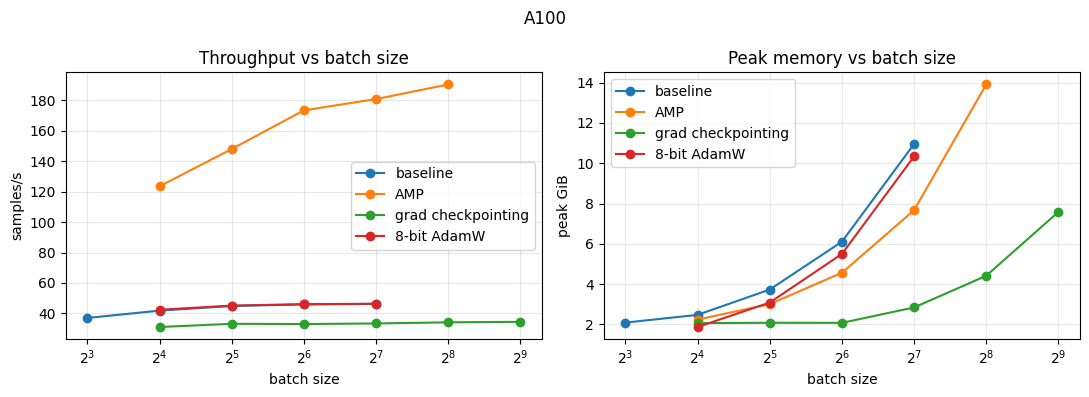

| Technique | Max batch | Throughput (samp/s) | Peak memory (GB) | Eval accuracy (test) |
|---|---|---|---|---|
| Baseline (HW4 settings) | 128 | 46.3 | 10.95 | 0.713 (val 0.664) [bs16 run] |
| Mixed precision | 256 | 187.3 | 13.91 | 0.612 (val 0.591) |
| Gradient checkpointing | 512 | 34.6 | 7.58 | 0.577 (val 0.555) |
| 8-bit optimiser | 128 | 46.5 | 10.34 | 0.683 (val 0.636) |
| Gradient accumulation (16 x 16) | 256 | 45.7 | 2.90 | 0.617 (val 0.583) |
| Best combination: AMP + 8-bit AdamW | 256 | 188.9 | 13.29 | 0.612 (val 0.593) |


In [18]:
import json, os, glob
import matplotlib; import matplotlib.pyplot as plt
R='results'
def scan(p):
    f=f'{R}/{p}_summary.json'
    return [r for r in json.load(open(f)) if not r['oom']] if os.path.exists(f) else []
curves={'baseline':scan('scale'),'AMP':scan('scan_amp'),'grad checkpointing':scan('scan_grad_ckpt'),'8-bit AdamW':scan('scan_adamw8bit')}
fig,ax=plt.subplots(1,2,figsize=(11,4))
for n,rows in curves.items():
    if not rows: continue
    x=[r['batch_size'] for r in rows]
    ax[0].plot(x,[r['samples_per_s'] for r in rows],'o-',label=n); ax[1].plot(x,[r['peak_mem_mb']/1024 for r in rows],'o-',label=n)
for a,t,y in zip(ax,['Throughput vs batch size','Peak memory vs batch size'],['samples/s','peak GiB']):
    a.set_xscale('log',base=2); a.set_xlabel('batch size'); a.set_ylabel(y); a.set_title(t); a.grid(alpha=.3); a.legend()
fig.suptitle(open('/tmp/gpu.txt').read().strip() if os.path.exists('/tmp/gpu.txt') else 'A100'); fig.tight_layout(); fig.savefig(f'{R}/fig_throughput_memory_vs_batch.png',dpi=150); plt.show()

# Table HW4.5.1
P=json.load(open(f'{R}/part_b_full.json')); base=json.load(open(f'{R}/baseline.json'))
bmax=curves['baseline'][-1]
def acc(r): return f"{r['test_acc']:.3f} (val {r['best_val_acc']:.3f})"
plain=[g['plain_large_batch'] for g in P['accum']]+[]
bm_eval=next((p for p in plain if p['batch']==bmax['batch_size'] and not p['oom']),None)
rows=[('Baseline (HW4 settings)',bmax['batch_size'],bmax['samples_per_s'],bmax['peak_mem_mb']/1024,
       acc(bm_eval) if bm_eval else f"{base['test_acc']:.3f} (val {base['best_val_acc']:.3f}) [bs16 run]")]
for k,n in [('amp','Mixed precision'),('grad_ckpt','Gradient checkpointing'),('adamw8bit','8-bit optimiser')]:
    r=P['max_batch'][k]; rows.append((n,r['batch'],r['samples_per_s'],r['peak_mem_mb']/1024,acc(r)))
g=P['accum'][-1]['accumulated']; rows.append((f"Gradient accumulation (16 x {g['effective_batch']//16})",g['effective_batch'],g['samples_per_s'],g['peak_mem_mb']/1024,acc(g)))
best=max([c for c in P['combo'] if not c['oom']],key=lambda c:c['samples_per_s']); rows.append(('Best combination: AMP + 8-bit AdamW',best['batch'],best['samples_per_s'],best['peak_mem_mb']/1024,acc(best)))
print('| Technique | Max batch | Throughput (samp/s) | Peak memory (GB) | Eval accuracy (test) |\n|---|---|---|---|---|')
for r in rows: print(f"| {r[0]} | {r[1]} | {r[2]:.1f} | {r[3]:.2f} | {r[4]} |")

## 5. HW4.a-2 - vLLM: different model + your own prompt
Edit the `--prompt` text to your own question.

In [19]:
!pip -q install vllm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.2.2 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.


In [20]:
%cd /content/hw45
!python vllm_demo.py --model Qwen/Qwen2.5-1.5B-Instruct --prompt "Explain in two sentences why a bigger batch size can make GPU training faster but use more memory." --prompt "Write a one-line tweet that sounds negative but is actually a joke."

/content/hw45
W1103 08:52:32.897000 19260 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1103 08:52:32.898000 19260 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1103 08:52:32.899000 19260 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead
config.json: 100% 660/660 [00:00<00:00, 2.56MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 20.9MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 54.2MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 93.9MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 100MB/s]
(MainProcess pid=19260) INFO 11-03 08:52:40 [startup.py:96] non-default args: {'dtype': 'float16', 'max_model_len': 2048, 'gpu_memory_utilization': 0.3, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
(MainProcess pid=19260) INFO 11-03 08:53:00 [model.py:744] Resolved architecture: Qwen2ForCausalLM
(MainProcess p

## 6. Table HW4.1 - HF pipeline batch 1 vs vLLM batch 1 / 8 / 32 (ms)

In [21]:
!python vllm_bench.py --model Qwen/Qwen2.5-0.5B-Instruct --max-new 128 --n-prompts 64 --gpu-util 0.80 --max-model-len 2048

config.json: 100% 659/659 [00:00<00:00, 3.62MB/s]

model.safetensors: downloading bytes:   4% 42.0M/988M [00:00<00:12, 77.5MB/s,  703kB/s  ]
model.safetensors: downloading bytes:  18% 182M/988M [00:01<00:03, 259MB/s, 14.4MB/s  ]
model.safetensors: downloading bytes:  39% 389M/988M [00:01<00:02, 255MB/s, 33.7MB/s  ]
model.safetensors: downloading bytes:  46% 454M/988M [00:02<00:02, 234MB/s, 37.3MB/s  ]
model.safetensors: downloading bytes:  49% 485M/988M [00:02<00:02, 210MB/s, 41.5MB/s  ]
model.safetensors: downloading bytes:  60% 596M/988M [00:02<00:01, 246MB/s, 49.1MB/s  ]
model.safetensors: downloading bytes:  67% 664M/988M [00:03<00:01, 198MB/s, 54.7MB/s  ]
model.safetensors: downloading bytes:  77% 758M/988M [00:03<00:00, 255MB/s, 60.3MB/s  ]
model.safetensors: downloading bytes:  85% 836M/988M [00:03<00:00, 208MB/s, 66.4MB/s  ]
model.safetensors: reconstructing file:  81% 805M/988M [00:04<00:00, 267MB/s, 56.7MB/s  ]
model.safetensors: reconstructing file:  88% 872M/988M [00:04<00:

## 7. Part D.2 - KV cache vs context length (measured + engine capacity + memory-bound longest context)

In [22]:
!python kv_cache.py theory --model Qwen/Qwen2.5-0.5B-Instruct --batch 8 --tokens 2048
!python kv_measure.py --model Qwen/Qwen2.5-0.5B-Instruct --batch 8 --lengths 512 1024 2048 4096 8192 16384

{
  "layers": 24,
  "kv_heads": 2,
  "head_dim": 64,
  "dtype_bytes": 2,
  "bytes_per_token": 12288,
  "batch": 8,
  "tokens": 2048,
  "total_gb": 0.1875
}
Loading weights: 100% 290/290 [00:00<00:00, 386.47it/s]
len    512: KV measured      48.0 MiB | formula      48.0 MiB
len   1024: KV measured      96.0 MiB | formula      96.0 MiB
len   2048: KV measured     192.0 MiB | formula     192.0 MiB
len   4096: KV measured     384.0 MiB | formula     384.0 MiB
len   8192: KV measured     768.0 MiB | formula     768.0 MiB
len  16384: KV measured    1536.0 MiB | formula    1536.0 MiB


Memory-bound longest context at batch 8: restrict vLLM's GPU budget to 8% of the card (~3.3 GB on a 40 GB A100) so the KV cache, not the model's 32,768-token limit, is the constraint. State this budget in METRICS. ~8 min.

In [23]:
!python kv_cache.py probe --model Qwen/Qwen2.5-0.5B-Instruct --batch 8 --gpu-util 0.08 --start 4096

len 4096: FAIL  <- RuntimeError: Engine core initialization failed. See root cause above. Failed core proc(s): {}
len 2048: FAIL  <- RuntimeError: Engine core initialization failed. See root cause above. Failed core proc(s): {}
len 1024: FAIL  <- RuntimeError: Engine core initialization failed. See root cause above. Failed core proc(s): {}
len 512: FAIL  <- RuntimeError: Engine core initialization failed. See root cause above. Failed core proc(s): {}
len 256: FAIL  <- RuntimeError: Engine core initialization failed. See root cause above. Failed core proc(s): {}
len 128: FAIL  <- RuntimeError: Engine core initialization failed. See root cause above. Failed core proc(s): {}
len 64: FAIL  <- RuntimeError: Engine core initialization failed. See root cause above. Failed core proc(s): {}
{
  "model": "Qwen/Qwen2.5-0.5B-Instruct",
  "batch": 8,
  "gpu_util": 0.08,
  "longest_ok_tokens": 0,
  "model_position_cap": 32768,
  "limited_by": "memory/engine limit",
  "last_failure": "RuntimeError: E

## 8. GPU-hours and download

In [24]:
import json
b=json.load(open('results/baseline.json'))
n=3488*3
print('samples per run =',n,'| train_time_s =',round(b['train_time_s'],1),'| samples/s =',round(n/b['train_time_s'],1))
!python gpu_hours.py --samples-per-s {n/b['train_time_s']} --dataset-size 3500 --epochs 3 --runs 1
!nvidia-smi -L > results/nvidia_smi_L.txt; cat results/nvidia_smi_L.txt
!zip -rq /content/hw45_results.zip results saved_bert
from google.colab import files; files.download('/content/hw45_results.zip')

samples per run = 10464 | train_time_s = 240.9 | samples/s = 43.4
wall-clock: 0.067 h   GPU-hours: 0.067
GPU 0: Tesla T4 (UUID: GPU-45a3688f-91da-aece-1fc4-c05b615f9aa2)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>